# Модель для прогнозирование стоимости


In [ ]:
import pandas as pd
import numpy as np
from numpy import radians, sin, cos, sqrt, arcsin
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, cross_validate, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.compose import TransformedTargetRegressor


In [6]:
df = pd.read_csv("realty_data.csv")

flats = df[df["city"] == "Москва"].copy()

In [7]:
Red_Square_lat = 55.75417 #информация с сайта https://time365.info/places/object/5163
Red_Square_lon = 37.62

def haversine_distance(lat, lon, center_lat=Red_Square_lat, center_lon=Red_Square_lon):
    earth_radius = 6371  
    lat = radians(lat)
    lon = radians(lon)
    center_lat = radians(center_lat)
    center_lon = radians(center_lon)
    # по формуле гаверсинуса
    dlat = lat - center_lat
    dlon = lon - center_lon
    a = (sin(dlat / 2) ** 2 + cos(center_lat) * cos(lat) * sin(dlon / 2) ** 2) 
    return 2 * earth_radius * arcsin(sqrt(a)) 

flats["distance_to_center_km"] = haversine_distance(flats["lat"], flats["lon"])

In [10]:
flats["is_first_floor"] = np.where(flats["floor"].eq(1), 1, 0) #признак первого этажа

bins = [0, 3, 5, 10, 15, 20, 30, float("inf")] #ценовые зоны по расстоянию
labels = [
    "0–3 км",
    "3–5 км",
    "5–10 км",
    "10–15 км",
    "15–20 км",
    "20–30 км",
    "30+ км"
]

flats["distance_zona"] = pd.cut(
    flats["distance_to_center_km"],
    bins=bins,
    labels=labels,
    right=False
).astype("object")

In [12]:
target = "price"

numeric_features_full = [
    "total_square",
    "rooms",
    "floor",
    "distance_to_center_km",
    "is_first_floor"
]

categorical_features_full = [
    "district",
    "source",
    "distance_zona"
]

features_full = numeric_features_full + categorical_features_full

model_data = flats[features_full + [target]].copy()

model_data = model_data[
    model_data["price"].notna() &
    (model_data["price"] > 0) &
    model_data["total_square"].notna() &
    (model_data["total_square"] > 0)
].copy()

In [13]:
X_full = model_data[features_full]
y = model_data[target]

X_train, X_test, y_train, y_test = train_test_split(
    X_full,
    y,
    test_size=0.20,
    random_state=42
)

In [14]:
def regression_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    return {
        "MAE, млн рублей": mae / 1_000_000,
        "RMSE, млн рублей": rmse / 1_000_000,
        "R2": r2
    }


In [16]:
try:
    one_hot_dense = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    one_hot_dense = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

def build_preprocessor(numeric_features, categorical_features, scale_numeric=False):
    if scale_numeric:
        numeric_transformer = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ])
    else:
        numeric_transformer = Pipeline([
            ("imputer", SimpleImputer(strategy="median"))
        ])

    categorical_transformer = Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value="Unknown"
            )
        ),
        (
            "onehot",
            one_hot_dense
        )
    ])

    return ColumnTransformer([
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ])


In [17]:
#линейная модель
linear_preprocessor = build_preprocessor(
    numeric_features_full,
    categorical_features_full,
    scale_numeric=True
)

linear_model = Pipeline([
    ("preprocessor", linear_preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)

linear_pred = linear_model.predict(X_test)

linear_metrics = regression_metrics(
    y_test,
    linear_pred
)


In [18]:
#Random Forest
tree_preprocessor = build_preprocessor(
    numeric_features_full,
    categorical_features_full,
    scale_numeric=False
)

rf_model = Pipeline([
    ("preprocessor", tree_preprocessor),
    (
        "model",
        RandomForestRegressor(
            n_estimators=250,
            max_depth=16,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1
        )
    )
])

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

rf_metrics = regression_metrics(
    y_test,
    rf_pred
)

In [19]:
#Gradient Boosting
gb_model = Pipeline([
    ("preprocessor", tree_preprocessor),
    (
        "model",
        GradientBoostingRegressor(
            n_estimators=200,
            learning_rate=0.05,
            max_depth=3,
            min_samples_leaf=5,
            random_state=42
        )
    )
])

gb_model.fit(X_train, y_train)

gb_pred = gb_model.predict(X_test)

gb_metrics = regression_metrics(
    y_test,
    gb_pred
)

In [20]:
#кросс валидация
cv = KFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

scoring = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2"
}

models_for_cv = {
    "Linear Regression": linear_model,
    "Random Forest": rf_model,
    "Gradient Boosting": gb_model
}

cv_rows = []

for name, model in models_for_cv.items():
    scores = cross_validate(
        model,
        X_full,
        y,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_rows.append({
        "Model": name,
        "CV MAE, млн р": -scores["test_mae"].mean() / 1_000_000,
        "CV MAE разброс, млн р": scores["test_mae"].std() / 1_000_000,
        "CV RMSE, млн р": -scores["test_rmse"].mean() / 1_000_000,
        "CV R2": scores["test_r2"].mean(),
        "CV R2 разброс": scores["test_r2"].std()
    })

cv_results = pd.DataFrame(cv_rows).set_index("Model")
cv_results.round(3)


,"CV MAE, млн р","CV MAE разброс, млн р","CV RMSE, млн р",CV R2,CV R2 разброс
Model,,,,,
Linear Regression,8.053,0.003,17.329,0.816,0.004
Random Forest,4.472,0.021,12.341,0.907,0.003
Gradient Boosting,6.046,0.012,14.253,0.876,0.002


на этот момент точная модель Random Forest. От линейной модели можно отказаться

In [ ]:
if len(X_train) > 40000:
    tuning_idx = X_train.sample(
        n=40000,
        random_state=42
    ).index

    X_tune = X_train.loc[tuning_idx]
    y_tune = y_train.loc[tuning_idx]
else:
    X_tune = X_train
    y_tune = y_train


In [22]:
#Подбор гиперпараметров градиентного бустинга
gb_search_pipeline = Pipeline([
    ("preprocessor", tree_preprocessor),
    ("model", GradientBoostingRegressor(random_state=42))
])

param_distributions = {
    "model__n_estimators": [100, 150, 200, 300, 400],
    "model__learning_rate": [0.02, 0.03, 0.05, 0.08, 0.1],
    "model__max_depth": [2, 3, 4, 5],
    "model__min_samples_leaf": [3, 5, 10, 20],
    "model__subsample": [0.7, 0.8, 0.9, 1.0]
}

gb_search = RandomizedSearchCV(
    estimator=gb_search_pipeline,
    param_distributions=param_distributions,
    n_iter=15,
    scoring="neg_mean_absolute_error",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

gb_search.fit(X_tune, y_tune)

print(gb_search.best_params_)

Fitting 3 folds for each of 15 candidates, totalling 45 fits
{'model__subsample': 0.9, 'model__n_estimators': 400, 'model__min_samples_leaf': 5, 'model__max_depth': 5, 'model__learning_rate': 0.08}


In [23]:
best_gb_model = gb_search.best_estimator_

best_gb_model.fit(X_train, y_train)

best_gb_pred = best_gb_model.predict(X_test)

best_gb_metrics = regression_metrics(
    y_test,
    best_gb_pred
)

In [24]:
#Подбор гиперпараметров random forest
rf_search_pipeline = Pipeline([
    ("preprocessor", tree_preprocessor),
    ("model", RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ))
])

rf_param_distributions = {
    "model__n_estimators": [100, 200, 300, 400, 500],
    "model__max_depth": [None, 10, 15, 20, 30],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 5, 10],
    "model__max_features": ["sqrt", "log2", 0.7, 1.0]
}

rf_search = RandomizedSearchCV(
    estimator=rf_search_pipeline,
    param_distributions=rf_param_distributions,
    n_iter=15,
    scoring="neg_mean_absolute_error",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X_tune, y_tune)

print(rf_search.best_params_)

Fitting 3 folds for each of 15 candidates, totalling 45 fits
{'model__n_estimators': 500, 'model__min_samples_split': 5, 'model__min_samples_leaf': 1, 'model__max_features': 0.7, 'model__max_depth': 20}


In [46]:
best_rf = rf_search.best_estimator_

best_rf.fit(X_train, y_train)

best_rf_pred = best_rf.predict(X_test)

best_rf_metrics = regression_metrics(
    y_test,
    best_rf_pred
)

In [27]:
#кросс валидация 2
models_for_cv_tuned = {
    "Tuned Random Forest": best_rf,
    "Tuned Gradient Boosting": best_gb_model
}

cv_rows = []

for name, model in models_for_cv_tuned.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_rows.append({
        "Model": name,
        "CV MAE, млн р": -scores["test_mae"].mean() / 1_000_000,
        "CV MAE разброс, млн р": scores["test_mae"].std() / 1_000_000,
        "CV RMSE, млн р": -scores["test_rmse"].mean() / 1_000_000,
        "CV R2": scores["test_r2"].mean(),
        "CV R2 разброс": scores["test_r2"].std()
    })

cv_tuned_results = pd.DataFrame(cv_rows).set_index("Model")
cv_tuned_results.round(3)

,"CV MAE, млн р","CV MAE разброс, млн р","CV RMSE, млн р",CV R2,CV R2 разброс
Model,,,,,
Tuned Random Forest,4.066,0.057,11.539,0.917,0.012
Tuned Gradient Boosting,4.612,0.014,11.698,0.915,0.010


Оставляем лучшую модель - Tuned Random Forest

In [47]:
# из анализа датасета было видно, что цены недвижимости имеют длинный правый хвост
# проверим, улучшит ли log(1 + price) качество на основной массе объектов

y_train_log = np.log1p(y_train)

best_model_params = {
    key.replace("model__", ""): value
    for key, value in rf_search.best_params_.items()
}

rf_log_model = Pipeline([
    ("preprocessor", tree_preprocessor),
    (
        "model",
        RandomForestRegressor(
            **best_model_params,
            random_state=42,
            n_jobs=-1
        )
    )
])

rf_log_model.fit(
    X_train,
    y_train_log
)

rf_log_pred_log = rf_log_model.predict(X_test)
# возвращаем прогноз обратно в рубли
rf_log_pred = np.expm1(rf_log_pred_log)

rf_log_metrics = regression_metrics(
    y_test,
    rf_log_pred
)

In [ ]:
#валидация 3

rf_log_cv_model = TransformedTargetRegressor(
    regressor=best_rf,
    func=np.log1p,
    inverse_func=np.expm1
)

models_for_cv_tuned = {
    "Tuned Random Forest": best_rf,
    "Tuned Gradient Boosting": best_gb_model,
    "Tuned Random Forest log": rf_log_cv_model
}

cv_rows = []

for name, model in models_for_cv_tuned.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_rows.append({
        "Model": name,
        "CV MAE, млн р": -scores["test_mae"].mean() / 1_000_000,
        "CV MAE разброс, млн р": scores["test_mae"].std() / 1_000_000,
        "CV RMSE, млн р": -scores["test_rmse"].mean() / 1_000_000,
        "CV R2": scores["test_r2"].mean(),
        "CV R2 разброс": scores["test_r2"].std()
    })

cv_tuned_results = (
    pd.DataFrame(cv_rows)
    .set_index("Model")
)

cv_tuned_results.round(3)

,"CV MAE, млн р","CV MAE разброс, млн р","CV RMSE, млн р",CV R2,CV R2 разброс
Model,,,,,
Tuned Random Forest,4.066,0.057,11.539,0.917,0.012
Tuned Gradient Boosting,4.612,0.014,11.698,0.915,0.010
Tuned Random Forest + log(price),4.021,0.074,11.807,0.913,0.017


,or_feature,importance
7,total_square,0.703246
0,distance_to_center_km,0.132378
5,rooms,0.079747
2,district,0.041614
6,source,0.014595
1,distance_zona,0.013840
3,floor,0.012523
4,is_first_floor,0.002057


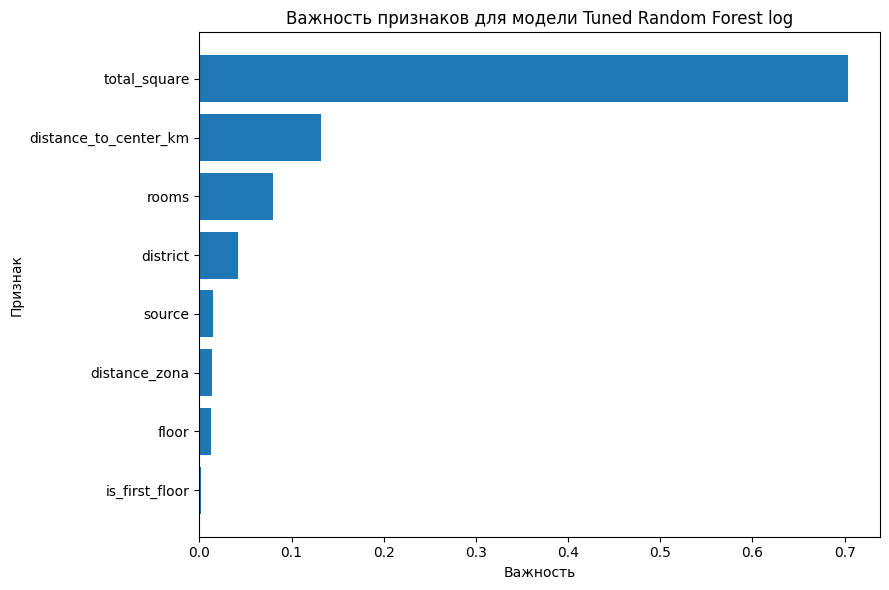

In [37]:
#анализ важности признаков для обучение модели Tuned Random Forest log

rf_log_preprocessor = rf_log_model.named_steps["preprocessor"]
rf_log_forest = rf_log_model.named_steps["model"]

rf_log_feature_names = rf_log_preprocessor.get_feature_names_out()


rf_log_importance = pd.DataFrame({
    "feature": rf_log_feature_names,
    "importance": rf_log_forest.feature_importances_
}).sort_values(
    "importance",
    ascending=False
)

rf_log_importance_grouped = rf_log_importance.copy()

def get_original_feature(name):
    name = name.replace("num__", "").replace("cat__", "")

    for feature in numeric_features_full:
        if name == feature:
            return feature

    for feature in categorical_features_full:
        if name.startswith(feature + "_"):
            return feature

    return name

rf_log_importance_grouped["or_feature"] = (
    rf_log_importance_grouped["feature"]
    .apply(get_original_feature)
)

rf_log_importance_summary = (
    rf_log_importance_grouped
    .groupby("or_feature", as_index=False)["importance"]
    .sum()
    .sort_values("importance", ascending=False)
)

display(rf_log_importance_summary)

plot_data = rf_log_importance_summary.sort_values("importance")

fig, ax = plt.subplots(figsize=(9, 6))

ax.barh(
    plot_data["or_feature"],
    plot_data["importance"]
)

ax.set_title("Важность признаков для модели Tuned Random Forest log")
ax.set_xlabel("Важность")
ax.set_ylabel("Признак")

plt.tight_layout()
plt.show()

In [ ]:
#Анализ ошибок лучшей модели
errors = X_test.copy()

errors["actual_price_mln"] = y_test / 1_000_000
errors["predicted_price_mln"] = rf_log_pred / 1_000_000

# ошибка со знаком:
# > 0 — модель завысила цену
# < 0 — модель занизила цену
errors["error_mln"] = (
    errors["predicted_price_mln"] -
    errors["actual_price_mln"]
)

# абсолютная ошибка
errors["absolute_error_mln"] = (
    errors["error_mln"].abs()
)

# 15 объектов с самыми большими ошибками
largest_errors = errors.nlargest(
    15,
    "absolute_error_mln"
)[[
    "total_square",
    "rooms",
    "floor",
    "is_first_floor",
    "distance_to_center_km",
    "distance_zona",
    "district",
    "source",
    "actual_price_mln",
    "predicted_price_mln",
    "error_mln",
    "absolute_error_mln"
]]

largest_errors

,total_square,rooms,floor,is_first_floor,distance_to_center_km,distance_zona,district,source,actual_price_mln,predicted_price_mln,error_mln,absolute_error_mln
17328,941.00,10.0,16.0,0,8.440796,5–10 км,Раменки район,Домклик,1155.219000,547.194655,-608.024345,608.024345
13578,920.00,6.0,1.0,1,2.021532,0–3 км,Басманный район,ЦИАН,907.044000,651.166079,-255.877921,255.877921
35962,764.00,NaN,14.0,0,9.325780,5–10 км,Ломоносовский район,ЦИАН,599.999999,388.959754,-211.040245,211.040245
61288,450.00,6.0,1.0,1,12.493406,10–15 км,Покровское-Стрешнево район,ЦИАН,435.000000,230.037254,-204.962746,204.962746
5622,872.60,10.0,8.0,0,1.667459,0–3 км,Таганский район,Домклик,900.000000,697.503427,-202.496573,202.496573
72564,595.00,NaN,13.0,0,6.050819,5–10 км,Раменки район,ЦИАН,523.666736,345.197773,-178.468963,178.468963
32073,550.00,6.0,6.0,0,1.985797,0–3 км,Пресненский район,Домклик,547.713900,371.331454,-176.382446,176.382446
65465,340.00,4.0,1.0,1,2.048669,0–3 км,Басманный район,Домклик,400.000000,227.705521,-172.294479,172.294479
10063,331.00,6.0,8.0,0,2.205418,0–3 км,Таганский район,ЦИАН,373.200000,228.428749,-144.771251,144.771251
18385,354.20,2.0,5.0,0,2.966113,0–3 км,Хамовники район,ЦИАН,423.424375,281.195929,-142.228446,142.228446


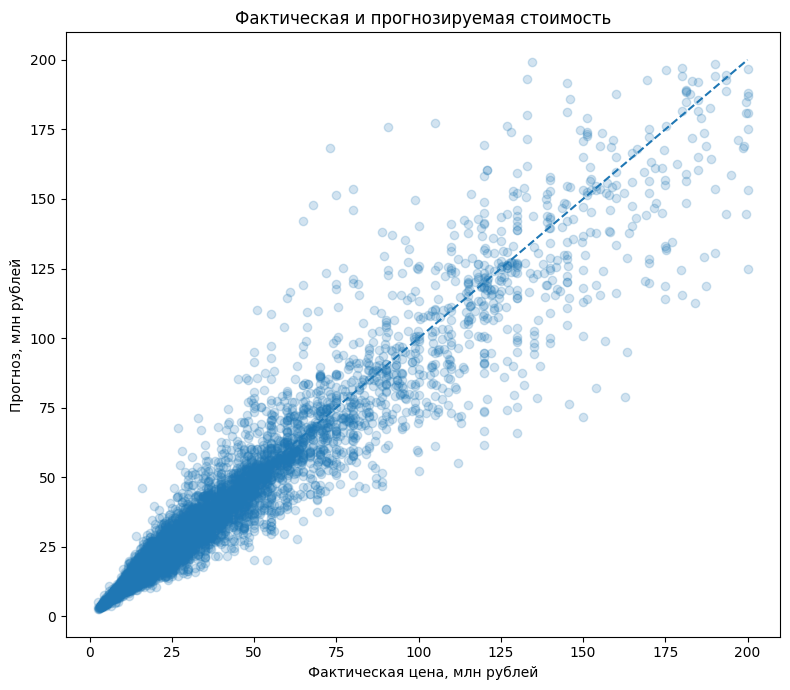

In [42]:
# Фактическая цена и прогноз
prediction_comparison = pd.DataFrame({
    "actual_mln": y_test / 1_000_000,
    "predicted_mln": rf_log_pred / 1_000_000
})

# убираем верхний 1% самых дорогих объектов,
# чтобы график основной массы квартир был читаемым
limit = prediction_comparison["actual_mln"].quantile(0.99)

plot_prediction = prediction_comparison[
    (prediction_comparison["actual_mln"] <= limit) &
    (prediction_comparison["predicted_mln"] <= limit)
]

fig, ax = plt.subplots(figsize=(8, 7))

ax.scatter(
    plot_prediction["actual_mln"],
    plot_prediction["predicted_mln"],
    alpha=0.20
)

min_value = min(
    plot_prediction["actual_mln"].min(),
    plot_prediction["predicted_mln"].min()
)

max_value = max(
    plot_prediction["actual_mln"].max(),
    plot_prediction["predicted_mln"].max()
)

# идеальная линия: прогноз = фактическая цена
ax.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

ax.set_xlabel("Фактическая цена, млн рублей")
ax.set_ylabel("Прогноз, млн рублей")
ax.set_title(
    "Фактическая и прогнозируемая стоимость"
)

plt.tight_layout()
plt.show()

In [48]:
#итог
models_for_cv_all = {
    "Linear Regression": linear_model,
    "Random Forest": rf_model,
    "Gradient Boosting": gb_model,
    "Tuned Random Forest": best_rf,
    "Tuned Gradient Boosting": best_gb_model,
    "Tuned Random Forest log": rf_log_cv_model
}

cv_rows = []

for name, model in models_for_cv_all.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_rows.append({
        "Model": name,

        "CV MAE, млн р":
            -scores["test_mae"].mean() / 1_000_000,

        "CV MAE разброс, млн р":
            scores["test_mae"].std() / 1_000_000,

        "CV RMSE, млн р":
            -scores["test_rmse"].mean() / 1_000_000,

        "CV RMSE разброс, млн р":
            scores["test_rmse"].std() / 1_000_000,

        "CV R2":
            scores["test_r2"].mean(),

        "CV R2 разброс":
            scores["test_r2"].std()
    })


cv_all_results = (
    pd.DataFrame(cv_rows)
    .set_index("Model")
    .sort_values("CV MAE, млн р")
)

cv_all_results.round(3)

,"CV MAE, млн р","CV MAE разброс, млн р","CV RMSE, млн р","CV RMSE разброс, млн р",CV R2,CV R2 разброс
Model,,,,,,
Tuned Random Forest log,4.021,0.074,11.807,1.402,0.913,0.017
Tuned Random Forest,4.066,0.057,11.539,1.065,0.917,0.012
Tuned Gradient Boosting,4.612,0.014,11.698,0.914,0.915,0.010
Random Forest,4.614,0.040,12.765,0.805,0.898,0.009
Gradient Boosting,6.013,0.007,14.017,0.633,0.878,0.007
Linear Regression,8.007,0.040,17.004,0.395,0.820,0.010
